# Sonar Rock vs Mine Classification with PCA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Circle, Ellipse, FancyArrowPatch, Rectangle, FancyBboxPatch
from scipy.stats import binomtest
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import sklearn, xgboost
import warnings
warnings.filterwarnings('ignore')

print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

scikit-learn 1.9.1 | xgboost 3.2.0


In [2]:
df = pd.read_csv(r"D:\DataMining\sonar_data.csv")
print(f"Shape: {df.shape}")
print(f"Missing values: {df.isna().sum().sum()}")
print(df['target'].value_counts())

Shape: (208, 61)
Missing values: 0
target
M    111
R     97
Name: count, dtype: int64


In [3]:
X = df.drop('target', axis=1)
le = LabelEncoder()
y = le.fit_transform(df['target'])
print(dict(zip(le.classes_, le.transform(le.classes_))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42)

print(f"Train: {len(y_train)}  (M = {(y_train == 0).sum()}, R = {(y_train == 1).sum()})")
print(f"Test:  {len(y_test)}  (M = {(y_test == 0).sum()}, R = {(y_test == 1).sum()})")

{'M': np.int64(0), 'R': np.int64(1)}
Train: 176  (M = 94, R = 82)
Test:  32  (M = 17, R = 15)


In [4]:
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

In [5]:
pca = PCA(n_components=8)
X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

cum_var = np.cumsum(PCA().fit(X_train_std).explained_variance_ratio_)
print(f"PC1: {cum_var[0]*100:.2f}%   2 PCs: {cum_var[1]*100:.2f}%   8 PCs: {cum_var[7]*100:.2f}%   20 PCs: {cum_var[19]*100:.2f}%")

PC1: 20.77%   2 PCs: 40.39%   8 PCs: 69.59%   20 PCs: 89.03%


In [6]:
models = {
    "SVM": SVC(probability=True, kernel='rbf', C=2, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=120, max_depth=5, random_state=42),
    "MLP": MLPClassifier(random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=120, max_depth=5, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=120, learning_rate=0.12, max_depth=2,
                             subsample=0.8, colsample_bytree=0.8, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=120, learning_rate=0.1, max_depth=3, random_state=42),
    "Logistic Regression": LogisticRegression(),
    "AdaBoost": AdaBoostClassifier(n_estimators=120, learning_rate=0.1, random_state=42),
    "Naive Bayes": GaussianNB(),
}

In [7]:
results = []
pred_pca = {}
cm_pca = {}

print("PCA (8 components):")
for name, model in models.items():
    model.fit(X_train_pca, y_train)
    y_pred = model.predict(X_test_pca)
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
    cm = confusion_matrix(y_test, y_pred)
    pred_pca[name] = y_pred
    cm_pca[name] = cm
    results.append([name, acc*100, prec*100, rec*100, f1*100, cm[0, 1], cm[1, 0]])

    print(f"{name}: {acc*100:.2f}%")
    print(classification_report(y_test, y_pred, target_names=["Mine", "Rock"]))
    print("Confusion Matrix:\n", cm)
    print("-"*60)

print("MLP iterations:", models["MLP"].n_iter_, "of", models["MLP"].max_iter)

PCA (8 components):
SVM: 96.88%
              precision    recall  f1-score   support

        Mine       1.00      0.94      0.97        17
        Rock       0.94      1.00      0.97        15

    accuracy                           0.97        32
   macro avg       0.97      0.97      0.97        32
weighted avg       0.97      0.97      0.97        32

Confusion Matrix:
 [[16  1]
 [ 0 15]]
------------------------------------------------------------


Random Forest: 90.62%
              precision    recall  f1-score   support

        Mine       0.89      0.94      0.91        17
        Rock       0.93      0.87      0.90        15

    accuracy                           0.91        32
   macro avg       0.91      0.90      0.91        32
weighted avg       0.91      0.91      0.91        32

Confusion Matrix:
 [[16  1]
 [ 2 13]]
------------------------------------------------------------
MLP: 90.62%
              precision    recall  f1-score   support

        Mine       0.85      1.00      0.92        17
        Rock       1.00      0.80      0.89        15

    accuracy                           0.91        32
   macro avg       0.93      0.90      0.90        32
weighted avg       0.92      0.91      0.90        32

Confusion Matrix:
 [[17  0]
 [ 3 12]]
------------------------------------------------------------


Extra Trees: 87.50%
              precision    recall  f1-score   support

        Mine       0.84      0.94      0.89        17
        Rock       0.92      0.80      0.86        15

    accuracy                           0.88        32
   macro avg       0.88      0.87      0.87        32
weighted avg       0.88      0.88      0.87        32

Confusion Matrix:
 [[16  1]
 [ 3 12]]
------------------------------------------------------------
XGBoost: 84.38%
              precision    recall  f1-score   support

        Mine       0.88      0.82      0.85        17
        Rock       0.81      0.87      0.84        15

    accuracy                           0.84        32
   macro avg       0.84      0.85      0.84        32
weighted avg       0.85      0.84      0.84        32

Confusion Matrix:
 [[14  3]
 [ 2 13]]
------------------------------------------------------------
KNN: 84.38%
              precision    recall  f1-score   support

        Mine       0.88      0.82      0.85  

Gradient Boosting: 81.25%
              precision    recall  f1-score   support

        Mine       0.79      0.88      0.83        17
        Rock       0.85      0.73      0.79        15

    accuracy                           0.81        32
   macro avg       0.82      0.81      0.81        32
weighted avg       0.82      0.81      0.81        32

Confusion Matrix:
 [[15  2]
 [ 4 11]]
------------------------------------------------------------
Logistic Regression: 78.12%
              precision    recall  f1-score   support

        Mine       0.78      0.82      0.80        17
        Rock       0.79      0.73      0.76        15

    accuracy                           0.78        32
   macro avg       0.78      0.78      0.78        32
weighted avg       0.78      0.78      0.78        32

Confusion Matrix:
 [[14  3]
 [ 4 11]]
------------------------------------------------------------


AdaBoost: 78.12%
              precision    recall  f1-score   support

        Mine       1.00      0.59      0.74        17
        Rock       0.68      1.00      0.81        15

    accuracy                           0.78        32
   macro avg       0.84      0.79      0.78        32
weighted avg       0.85      0.78      0.77        32

Confusion Matrix:
 [[10  7]
 [ 0 15]]
------------------------------------------------------------
Naive Bayes: 71.88%
              precision    recall  f1-score   support

        Mine       0.79      0.65      0.71        17
        Rock       0.67      0.80      0.73        15

    accuracy                           0.72        32
   macro avg       0.73      0.72      0.72        32
weighted avg       0.73      0.72      0.72        32

Confusion Matrix:
 [[11  6]
 [ 3 12]]
------------------------------------------------------------
MLP iterations: 200 of 200


In [8]:
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1",
                                            "Missed mines", "False alarms"])
results_df = results_df.sort_values("Accuracy", ascending=False, kind="stable").reset_index(drop=True)
results_df.round(2)

,Model,Accuracy,Precision,Recall,F1,Missed mines,False alarms
0,SVM,96.88,96.88,97.06,96.87,1,0
1,Random Forest,90.62,90.87,90.39,90.54,1,2
2,MLP,90.62,92.50,90.00,90.39,0,3
3,Extra Trees,87.50,88.26,87.06,87.30,1,3
4,XGBoost,84.38,84.38,84.51,84.36,3,2
5,KNN,84.38,84.38,84.51,84.36,3,2
6,Gradient Boosting,81.25,81.78,80.78,80.95,2,4
7,Logistic Regression,78.12,78.17,77.84,77.93,3,4
8,AdaBoost,78.12,84.09,79.41,77.58,7,0
9,Naive Bayes,71.88,72.62,72.35,71.85,6,3


In [9]:
best_model = results_df.loc[0, "Model"]
best_acc = results_df.loc[0, "Accuracy"]
print(f"Best Model: {best_model}  //  Best Accuracy = {best_acc:.2f}%")

Best Model: SVM  //  Best Accuracy = 96.88%


In [10]:
def mcnemar_p(pred_a, pred_b):
    a = pred_a == y_test
    b = pred_b == y_test
    only_a = (a & ~b).sum()
    only_b = (~a & b).sum()
    if only_a + only_b == 0:
        return 1.0
    return binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue

rows = []
for name, model in models.items():
    m = clone(model)
    m.fit(X_train_std, y_train)
    y_pred = m.predict(X_test_std)
    cm = confusion_matrix(y_test, y_pred)
    acc_pca = accuracy_score(y_test, pred_pca[name]) * 100
    acc_full = accuracy_score(y_test, y_pred) * 100
    rows.append([name, acc_pca, acc_full, cm_pca[name][0, 1], cm[0, 1],
                 cm_pca[name][1, 0], cm[1, 0], mcnemar_p(pred_pca[name], y_pred)])

compare_df = pd.DataFrame(rows, columns=["Model", "Acc PCA", "Acc no PCA", "Missed PCA", "Missed no PCA",
                                         "False alarms PCA", "False alarms no PCA", "McNemar p"])
print(f"Mean accuracy  PCA: {compare_df['Acc PCA'].mean():.2f}%   no PCA: {compare_df['Acc no PCA'].mean():.2f}%")
compare_df.round(2)

Mean accuracy  PCA: 84.38%   no PCA: 83.75%


,Model,Acc PCA,Acc no PCA,Missed PCA,Missed no PCA,False alarms PCA,False alarms no PCA,McNemar p
0,SVM,96.88,87.50,1,1,0,3,0.25
1,Random Forest,90.62,87.50,1,1,2,3,1.00
2,MLP,90.62,87.50,0,1,3,3,1.00
3,Extra Trees,87.50,90.62,1,0,3,3,1.00
4,XGBoost,84.38,87.50,3,0,2,4,1.00
5,KNN,84.38,78.12,3,2,2,5,0.69
6,Gradient Boosting,81.25,84.38,2,0,4,5,1.00
7,Logistic Regression,78.12,84.38,3,1,4,4,0.69
8,AdaBoost,78.12,90.62,7,1,0,2,0.29
9,Naive Bayes,71.88,59.38,6,9,3,4,0.29


In [11]:
def wilson(k, n, z=1.96):
    p = k / n
    center = (p + z**2 / (2*n)) / (1 + z**2 / n)
    half = z * np.sqrt(p*(1-p)/n + z**2 / (4*n**2)) / (1 + z**2 / n)
    return (center - half) * 100, (center + half) * 100

n = len(y_test)
for name in ["SVM", "Random Forest", "MLP"]:
    k = (pred_pca[name] == y_test).sum()
    low, high = wilson(k, n)
    print(f"{name}: {k}/{n}  95% Wilson interval {low:.2f}% - {high:.2f}%")

print(f"SVM vs Random Forest: McNemar p = {mcnemar_p(pred_pca['SVM'], pred_pca['Random Forest']):.3f}")
print(f"SVM vs MLP: McNemar p = {mcnemar_p(pred_pca['SVM'], pred_pca['MLP']):.3f}")

SVM: 31/32  95% Wilson interval 84.26% - 99.45%
Random Forest: 29/32  95% Wilson interval 75.78% - 96.76%
MLP: 29/32  95% Wilson interval 75.78% - 96.76%
SVM vs Random Forest: McNemar p = 0.500
SVM vs MLP: McNemar p = 0.625


In [12]:
sample = np.array([(0.0522,0.0437,0.0180,0.0292,0.0351,0.1171,0.1257,0.1178,0.1258,0.2529,
                    0.2716,0.2374,0.1878,0.0983,0.0683,0.1503,0.1723,0.2339,0.1962,0.1395,
                    0.3164,0.5888,0.7631,0.8473,0.9424,0.9986,0.9699,1.0000,0.8630,0.6979,
                    0.7717,0.7305,0.5197,0.1786,0.1098,0.1446,0.1066,0.1440,0.1929,0.0325,
                    0.1490,0.0328,0.0537,0.1309,0.0910,0.0757,0.1059,0.1005,0.0535,0.0235,
                    0.0155,0.0160,0.0029,0.0051,0.0062,0.0089,0.0140,0.0138,0.0077,0.0031)])
sample = pd.DataFrame(sample, columns=X.columns)
sample = pca.transform(scaler.transform(sample))

prediction = models[best_model].predict(sample)
label = "Rock" if prediction[0] == 1 else "Mine"
print(f"Prediction: {label}")

Prediction: Mine


## Figures

In [13]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
BLUE, ORANGE = "#1f77b4", "#e07b00"
feat = X.values

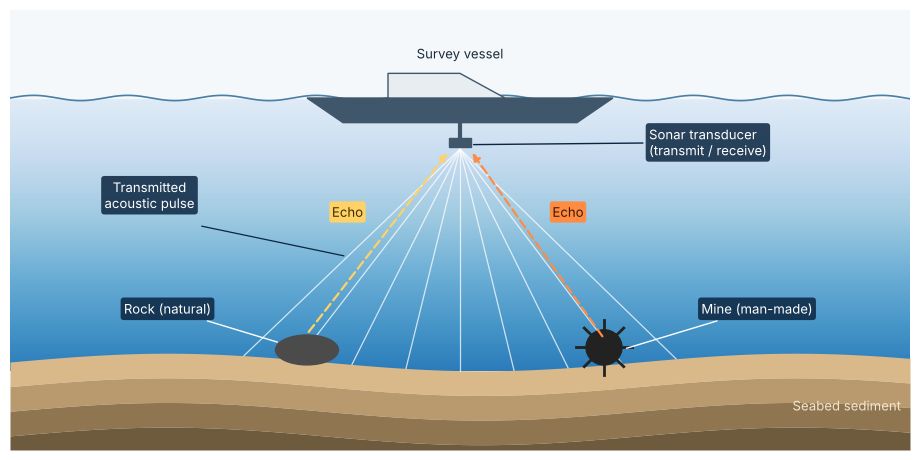

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.set_xlim(0, 10); ax.set_ylim(0, 5); ax.axis("off")
grad = np.linspace(0, 1, 100).reshape(-1, 1)
ax.imshow(grad, extent=[0, 10, 0.9, 4.0], origin="upper", cmap="Blues", vmin=-0.2, vmax=1.5, aspect="auto", zorder=0)
ax.add_patch(Rectangle((0, 4.0), 10, 1.0, color="#f4f8fb", zorder=0))
x = np.linspace(0, 10, 400)
ax.plot(x, 4.0 + 0.03*np.sin(6*x), color="#4a7fa5", lw=1.2, zorder=3)
bed = 1.0 + 0.10*np.sin(0.9*x)
for k, c in enumerate(["#d9b98a", "#b99a6e", "#8f7650"]):
    ax.fill_between(x, bed - 0.28*k - 0.28, bed - 0.28*k, color=c, zorder=1, lw=0)
ax.fill_between(x, 0, bed - 0.84, color="#6e5a3c", zorder=1, lw=0)
ax.add_patch(Polygon([[3.3, 4.0], [6.7, 4.0], [6.3, 3.72], [3.7, 3.72]], closed=True, color="#40566b", zorder=4))
ax.add_patch(Polygon([[4.2, 4.0], [4.2, 4.28], [5.0, 4.28], [5.5, 4.0]], closed=True, color="#e8edf2", ec="#40566b", zorder=4))
ax.plot([5.0, 5.0], [3.72, 3.52], color="#40566b", lw=3, zorder=4)
ax.add_patch(Rectangle((4.88, 3.44), 0.24, 0.1, color="#40566b", zorder=4))
src = np.array([5.0, 3.42])

def seabed_y(xv):
    return 1.0 + 0.10*np.sin(0.9*xv)

for xt in np.linspace(2.6, 7.4, 9):
    ax.plot([src[0], xt], [src[1], seabed_y(xt)], color="#ffffff", lw=0.9, alpha=0.75, zorder=2)
rock_x = 3.3
ax.add_patch(Ellipse((rock_x, seabed_y(rock_x)+0.12), 0.7, 0.34, color="#4b4b4b", zorder=3))
mine_x = 6.6
my = seabed_y(mine_x) + 0.2
ax.add_patch(Circle((mine_x, my), 0.2, color="#222", zorder=3))
for a in np.linspace(0, 2*np.pi, 9)[:-1]:
    ax.plot([mine_x+0.2*np.cos(a), mine_x+0.31*np.cos(a)], [my+0.2*np.sin(a), my+0.31*np.sin(a)], color="#222", lw=2, zorder=3)

def echo(px, py, col):
    ax.add_patch(FancyArrowPatch((px, py), (src[0]+(0.12 if px > src[0] else -0.12), src[1]-0.02), arrowstyle="-|>",
                                 mutation_scale=11, color=col, lw=1.6, ls=(0, (4, 2)), zorder=5, connectionstyle="arc3,rad=0.0"))

echo(rock_x, seabed_y(rock_x)+0.3, "#ffd166")
echo(mine_x, my+0.1, "#ff8c42")
box = dict(boxstyle="round,pad=0.25", fc="#0b2540", ec="none", alpha=0.85)
kw = dict(fontsize=9.5, zorder=6, color="white", bbox=box)
ax.text(5.0, 4.45, "Survey vessel", ha="center", fontsize=9.5, color="#1c2b39", zorder=6)
ax.annotate("Sonar transducer\n(transmit / receive)", xy=(5.12, 3.47), xytext=(7.1, 3.35), arrowprops=dict(arrowstyle="-", color="#0b2540"), **kw)
ax.text(1.55, 2.75, "Transmitted\nacoustic pulse", ha="center", **kw)
ax.annotate("", xy=(3.74, 2.2), xytext=(2.1, 2.55), arrowprops=dict(arrowstyle="-", color="#0b2540", lw=0.9))
lead = dict(arrowstyle="-", color="white", lw=1.0)
ax.annotate("Rock (natural)", xy=(rock_x-0.3, seabed_y(rock_x)+0.2), xytext=(1.75, 1.55), ha="center", arrowprops=lead, **kw)
ax.annotate("Mine (man-made)", xy=(mine_x+0.22, my-0.02), xytext=(8.3, 1.55), ha="center", arrowprops=lead, **kw)
ax.text(9.9, 0.45, "Seabed sediment", color="#f3e6cf", ha="right", fontsize=9.5, zorder=6)
ax.text(3.75, 2.65, "Echo", ha="center", fontsize=9.5, zorder=6, color="#3d2f00", bbox=dict(boxstyle="round,pad=0.2", fc="#ffd166", ec="none"))
ax.text(6.2, 2.65, "Echo", ha="center", fontsize=9.5, zorder=6, color="#3b1a00", bbox=dict(boxstyle="round,pad=0.2", fc="#ff8c42", ec="none"))
fig.subplots_adjust(0, 0, 1, 1)
fig.savefig("image.png", dpi=250)
plt.show()

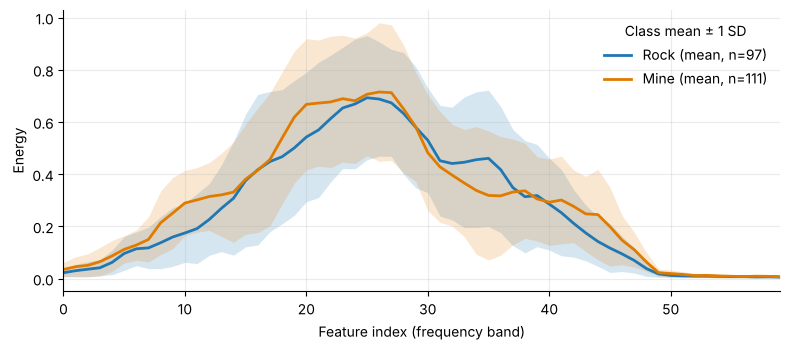

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.6))
xs = np.arange(60)
for lab, col, name in [(1, BLUE, "Rock"), (0, ORANGE, "Mine")]:
    mu = feat[y == lab].mean(0)
    sd = feat[y == lab].std(0)
    ax.plot(xs, mu, color=col, lw=2, label=f"{name} (mean, n={(y == lab).sum()})")
    ax.fill_between(xs, mu-sd, mu+sd, color=col, alpha=.18, lw=0)
ax.set_xlim(0, 59)
ax.set_xlabel("Feature index (frequency band)")
ax.set_ylabel("Energy")
ax.legend(frameon=False, title="Class mean ± 1 SD")
fig.tight_layout()
fig.savefig("f_classmeans_v3.png", dpi=250)
plt.show()

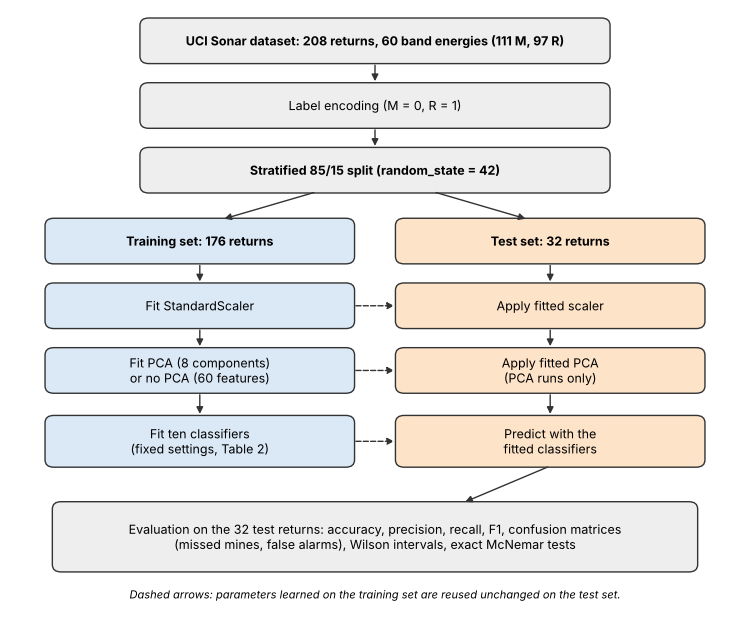

In [16]:
fig, ax = plt.subplots(figsize=(7.6, 6.4))
ax.set_xlim(0, 10); ax.set_ylim(0.6, 10.5); ax.axis("off")
GRAY, LBLUE, LORANGE = "#eeeeee", "#dbe9f6", "#fde3c8"

def box(xc, yc, w, h, text, fc, bold=False):
    ax.add_patch(FancyBboxPatch((xc - w/2, yc - h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fc, ec="#333333", lw=1))
    ax.text(xc, yc, text, ha="center", va="center", fontsize=9, fontweight="bold" if bold else "normal")

def arrow(x1, y1, x2, y2, ls="-"):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#333333", lw=1, linestyle=ls))

box(5, 10.0, 6.4, 0.7, "UCI Sonar dataset: 208 returns, 60 band energies (111 M, 97 R)", GRAY, True)
box(5, 8.95, 6.4, 0.7, "Label encoding (M = 0, R = 1)", GRAY)
box(5, 7.9, 6.4, 0.7, "Stratified 85/15 split (random_state = 42)", GRAY, True)
arrow(5, 9.65, 5, 9.3); arrow(5, 8.6, 5, 8.25)
box(2.6, 6.75, 4.2, 0.7, "Training set: 176 returns", LBLUE, True)
box(7.4, 6.75, 4.2, 0.7, "Test set: 32 returns", LORANGE, True)
arrow(4.2, 7.55, 2.9, 7.1); arrow(5.8, 7.55, 7.1, 7.1)
box(2.6, 5.7, 4.2, 0.7, "Fit StandardScaler", LBLUE)
box(2.6, 4.65, 4.2, 0.7, "Fit PCA (8 components)\nor no PCA (60 features)", LBLUE)
box(2.6, 3.5, 4.2, 0.8, "Fit ten classifiers\n(fixed settings, Table 2)", LBLUE)
arrow(2.6, 6.4, 2.6, 6.05); arrow(2.6, 5.35, 2.6, 5.0); arrow(2.6, 4.3, 2.6, 3.9)
box(7.4, 5.7, 4.2, 0.7, "Apply fitted scaler", LORANGE)
box(7.4, 4.65, 4.2, 0.7, "Apply fitted PCA\n(PCA runs only)", LORANGE)
box(7.4, 3.5, 4.2, 0.8, "Predict with the\nfitted classifiers", LORANGE)
arrow(7.4, 6.4, 7.4, 6.05); arrow(7.4, 5.35, 7.4, 5.0); arrow(7.4, 4.3, 7.4, 3.9)
arrow(4.7, 5.7, 5.3, 5.7, ls="--"); arrow(4.7, 4.65, 5.3, 4.65, ls="--"); arrow(4.7, 3.5, 5.3, 3.5, ls="--")
box(5, 1.95, 8.8, 1.1, "Evaluation on the 32 test returns: accuracy, precision, recall, F1, confusion matrices\n(missed mines, false alarms), Wilson intervals, exact McNemar tests", GRAY)
arrow(7.4, 3.1, 6.2, 2.5)
ax.text(5, 0.95, "Dashed arrows: parameters learned on the training set are reused unchanged on the test set.", ha="center", fontsize=8, style="italic")
fig.tight_layout()
fig.savefig("f_workflow_v3.png", dpi=250)
plt.show()

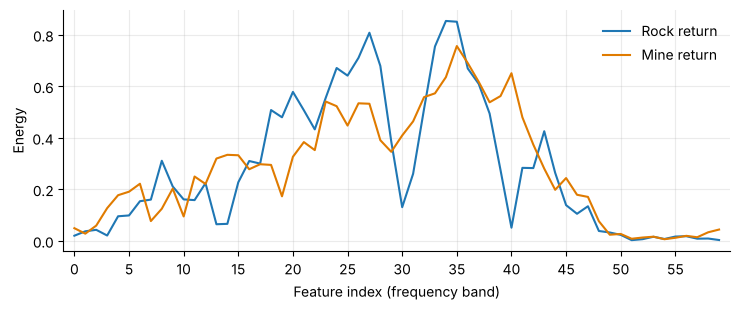

In [17]:
rock_i = np.where(y == 1)[0][0]
mine_i = np.where(y == 0)[0][0]

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(range(60), feat[rock_i], color=BLUE, label="Rock return")
ax.plot(range(60), feat[mine_i], color=ORANGE, label="Mine return")
ax.set_xticks(range(0, 60, 5))
ax.set_xlim(-1, 60)
ax.set_xlabel("Feature index (frequency band)")
ax.set_ylabel("Energy")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("f_signals_v3.png", dpi=250)
plt.show()

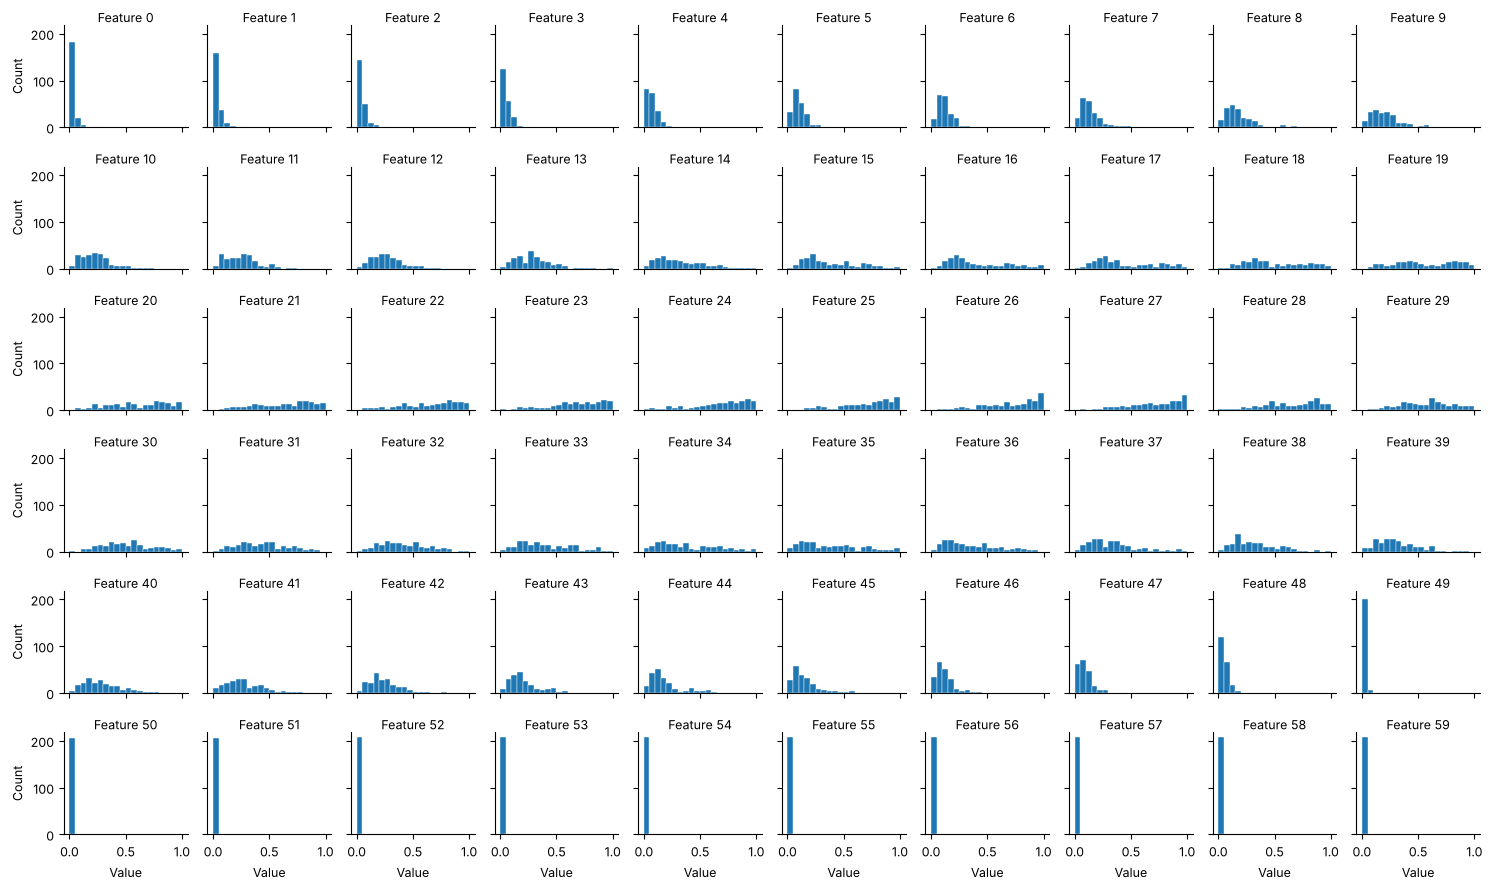

In [18]:
fig, axes = plt.subplots(6, 10, figsize=(15, 9.0), sharex=True, sharey=True)
for i, ax in enumerate(axes.ravel()):
    ax.hist(feat[:, i], bins=np.linspace(0, 1, 21), color=BLUE, edgecolor="white", lw=.3)
    ax.set_title(f"Feature {i}", fontsize=9, pad=2)
    ax.grid(False)
    ax.tick_params(labelsize=9)
for ax in axes[-1]:
    ax.set_xlabel("Value", fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("Count", fontsize=9)
fig.tight_layout()
fig.savefig("f_hist_v3.png", dpi=200)
plt.show()

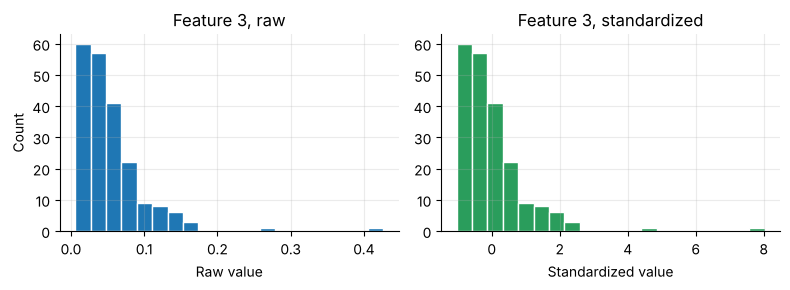

In [19]:
v = feat[:, 3]
z = (v - v.mean()) / v.std()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(8, 3.0))
a1.hist(v, bins=20, color=BLUE, edgecolor="white")
a1.set_title("Feature 3, raw")
a1.set_xlabel("Raw value")
a1.set_ylabel("Count")
a2.hist(z, bins=20, color="#2a9d5c", edgecolor="white")
a2.set_title("Feature 3, standardized")
a2.set_xlabel("Standardized value")
fig.tight_layout()
fig.savefig("f_feature3_v3.png", dpi=250)
plt.show()

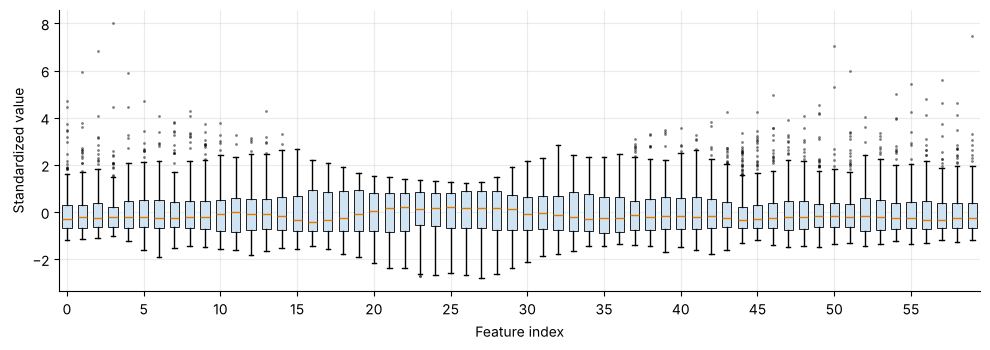

In [20]:
S = StandardScaler().fit_transform(feat)

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.boxplot(S, widths=.6, flierprops=dict(marker=".", ms=2, alpha=.5), medianprops=dict(color=ORANGE),
           patch_artist=True, boxprops=dict(facecolor="#cfe3f3", lw=.6))
ax.set_xticks(range(1, 61, 5), range(0, 60, 5))
ax.set_xlabel("Feature index")
ax.set_ylabel("Standardized value")
fig.tight_layout()
fig.savefig("f_box_v3.png", dpi=250)
plt.show()

Min correlation: -0.56


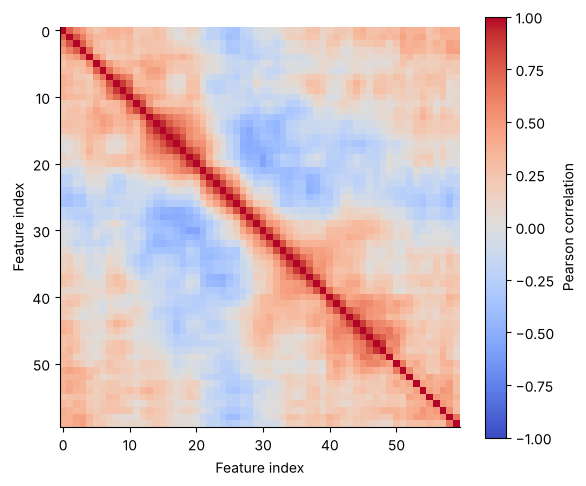

In [21]:
corr = np.corrcoef(X_train.values.T)
print(f"Min correlation: {corr.min():.2f}")

fig, ax = plt.subplots(figsize=(6.0, 5.0))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(0, 60, 10))
ax.set_yticks(range(0, 60, 10))
ax.set_xlabel("Feature index")
ax.set_ylabel("Feature index")
fig.colorbar(im, ax=ax, label="Pearson correlation")
fig.tight_layout()
fig.savefig("f_corr_train_v3.png", dpi=250)
plt.show()

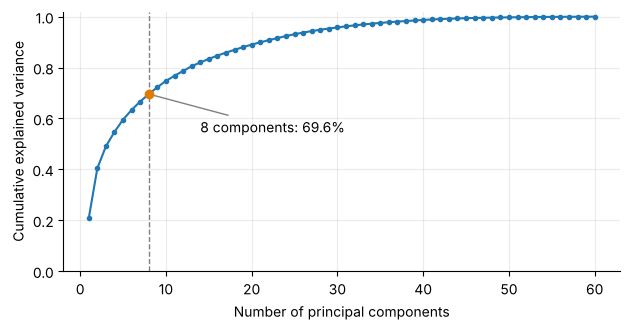

In [22]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(range(1, 61), cum_var, marker="o", ms=3, color=BLUE)
ax.axvline(8, ls="--", color="gray", lw=1)
ax.scatter([8], [cum_var[7]], color=ORANGE, zorder=5)
ax.annotate(f"8 components: {cum_var[7]*100:.1f}%", (8, cum_var[7]), xytext=(14, cum_var[7]-0.15),
            arrowprops=dict(arrowstyle="-", color="gray"))
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_ylim(0, 1.02)
fig.tight_layout()
fig.savefig("f_pcavar_v3.png", dpi=250)
plt.show()

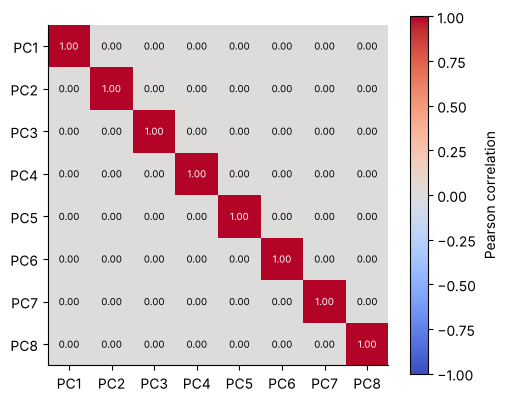

In [23]:
pc_corr = np.corrcoef(X_train_pca.T)

fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.imshow(pc_corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.grid(False)
for i in range(8):
    for j in range(8):
        ax.text(j, i, f"{pc_corr[i, j]:.2f}".replace("-0.00", "0.00"), ha="center", va="center", fontsize=7,
                color="white" if abs(pc_corr[i, j]) > .6 else "black")
ax.set_xticks(range(8), [f"PC{i+1}" for i in range(8)])
ax.set_yticks(range(8), [f"PC{i+1}" for i in range(8)])
fig.colorbar(im, ax=ax, label="Pearson correlation")
fig.tight_layout()
fig.savefig("f_pccorr_v3.png", dpi=250)
plt.show()

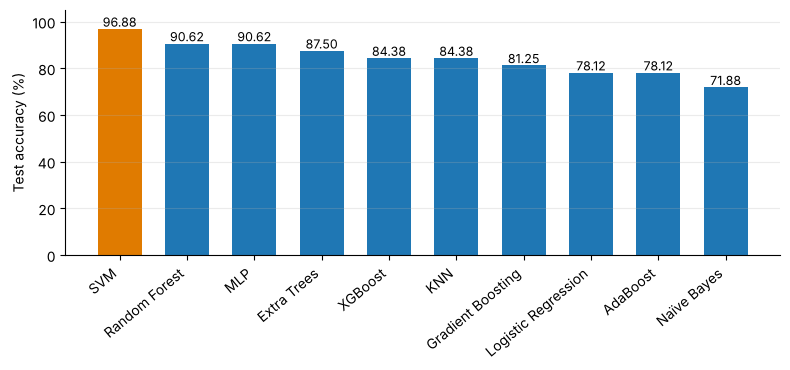

In [24]:
names = list(models.keys())
scores = [accuracy_score(y_test, pred_pca[n]) * 100 for n in names]
labels = [n.replace("Naive Bayes", "Naïve Bayes") for n in names]

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(labels, scores, color=[ORANGE] + [BLUE]*9, width=.65)
for b, s in zip(bars, scores):
    ax.text(b.get_x() + b.get_width()/2, s + 1, f"{s:.2f}", ha="center", fontsize=9)
ax.set_ylim(0, 105)
ax.set_ylabel("Test accuracy (%)")
ax.grid(axis="x", visible=False)
plt.xticks(rotation=40, ha="right")
fig.tight_layout()
fig.savefig("f_accuracy_v3.png", dpi=250)
plt.show()

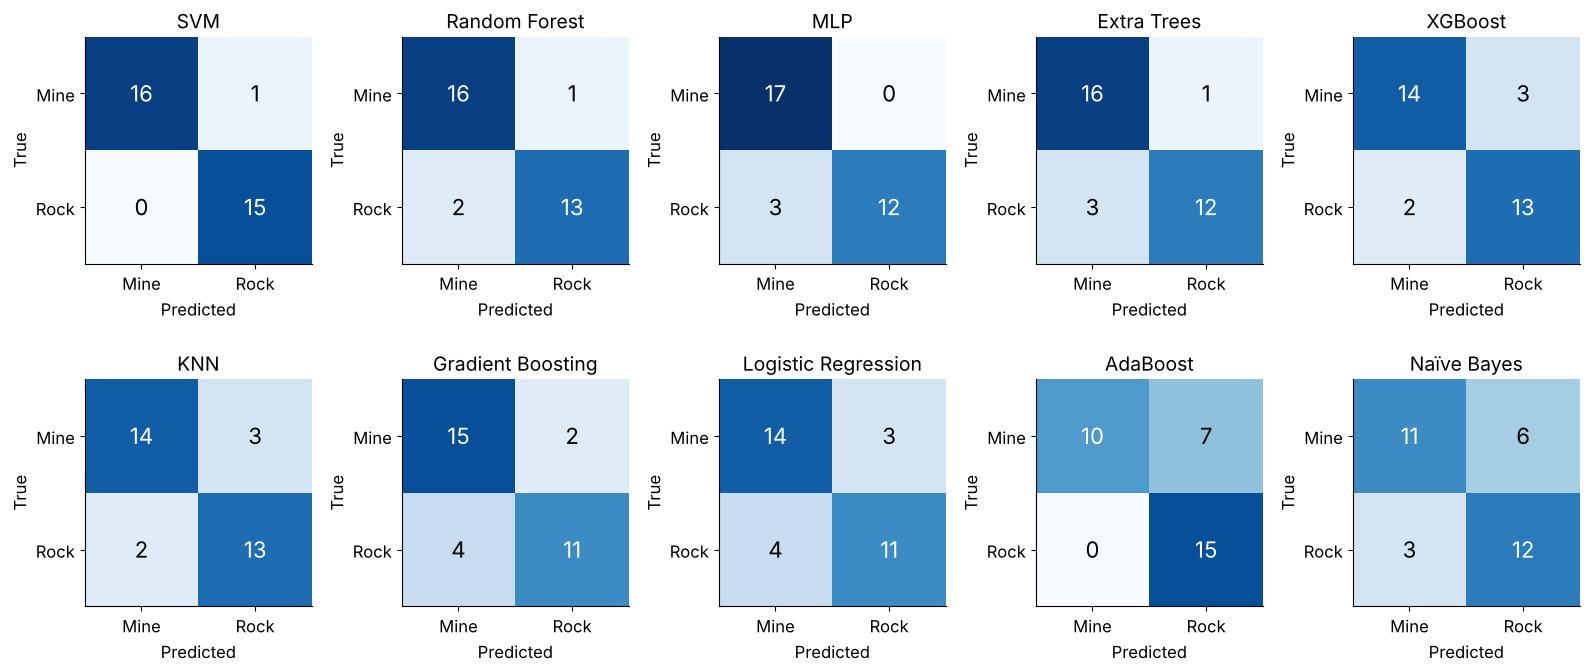

In [25]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, name in zip(axes.ravel(), names):
    cm = cm_pca[name]
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=17)
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 8 else "black", fontsize=16)
    ax.set_xticks([0, 1], ["Mine", "Rock"], fontsize=12)
    ax.set_yticks([0, 1], ["Mine", "Rock"], fontsize=12)
    ax.set_title(name.replace("Naive Bayes", "Naïve Bayes"), fontsize=14)
    ax.set_xlabel("Predicted", fontsize=12)
    ax.set_ylabel("True", fontsize=12)
fig.tight_layout()
fig.savefig("f_confusion_v3.png", dpi=200)
plt.show()